# SE match posterior: linear model 2 chgpt

\Delta: 20, n: 100, Lmin: 3, Lmax: 3


  0%|          | 0/1 [00:00<?, ?it/s]

  0%|          | 0/703 [00:00<?, ?it/s]

Sum of row weights:  [1313.30688252 1332.99223211 1353.70088537]


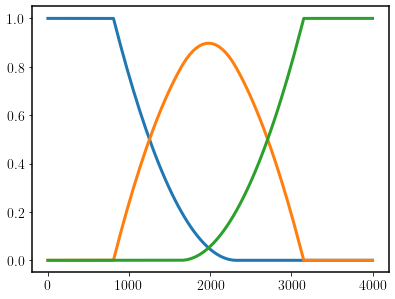

  0%|          | 0/13 [00:00<?, ?it/s]

  0%|          | 0/40 [00:00<?, ?it/s]

\Delta: 10, n: 50, Lmin: 3, Lmax: 3


  0%|          | 0/1 [00:00<?, ?it/s]

  0%|          | 0/153 [00:00<?, ?it/s]

  Tested 3999 valid positions
  Best 5 improvements: [(1243, Array(5374.40993631, dtype=float64), Array(5376.53253732, dtype=float64)), (1241, Array(5373.45341146, dtype=float64), Array(5377.48906216, dtype=float64)), (1244, Array(5373.27943696, dtype=float64), Array(5377.66303667, dtype=float64)), (1240, Array(5373.16860744, dtype=float64), Array(5377.77386619, dtype=float64)), (1242, Array(5372.57649711, dtype=float64), Array(5378.36597652, dtype=float64))]
  Tested 2400 valid positions
  Best 5 improvements: [(2534, Array(3622.98034657, dtype=float64), Array(1753.55219075, dtype=float64)), (2533, Array(3622.64594105, dtype=float64), Array(1753.88659628, dtype=float64)), (2576, Array(3622.21302196, dtype=float64), Array(1754.31951536, dtype=float64)), (2575, Array(3621.2680713, dtype=float64), Array(1755.26446602, dtype=float64)), (2535, Array(3621.01520388, dtype=float64), Array(1755.51733345, dtype=float64))]

Applying local refinement...


... (193 outputs left out)

  0%|          | 0/153 [00:00<?, ?it/s]

  Tested 3999 valid positions
  Best 5 improvements: [(1214, Array(4863.99809492, dtype=float64), Array(4932.46979388, dtype=float64)), (1210, Array(4863.62816732, dtype=float64), Array(4932.83972147, dtype=float64)), (1212, Array(4863.59421913, dtype=float64), Array(4932.87366967, dtype=float64)), (1211, Array(4863.43817057, dtype=float64), Array(4933.02971823, dtype=float64)), (1209, Array(4863.27753939, dtype=float64), Array(4933.19034941, dtype=float64))]
  Tested 2400 valid positions
  Best 5 improvements: [(2528, Array(3131.40739387, dtype=float64), Array(1801.06240001, dtype=float64)), (2527, Array(3131.28007257, dtype=float64), Array(1801.18972131, dtype=float64)), (2533, Array(3130.48843359, dtype=float64), Array(1801.98136029, dtype=float64)), (2534, Array(3130.23362619, dtype=float64), Array(1802.23616769, dtype=float64)), (2537, Array(3130.06529809, dtype=float64), Array(1802.40449579, dtype=float64))]

Applying local refinement...


100%|██████████| 40/40 [04:28<00:00,  6.72s/it]

b_hat, b:  [0.92898614 0.74266392 0.87628857] [0.92226903 0.74456637 0.87296639]
Theta cov:  [[2.24511437 0.53856869 0.10548845]
 [0.53856869 1.85999546 0.56379468]
 [0.10548845 0.56379468 2.20213194]]
V.T @ V / n:  [[2.27961478 0.5552014  0.09717283]
 [0.5552014  1.87965217 0.65910109]
 [0.09717283 0.65910109 2.21994291]]
nu.T @ ρ @ nu + kappa:  [[2.23463715 0.56169005 0.06835741]
 [0.56169005 1.81662085 0.60442391]
 [0.06835741 0.60442391 2.23171772]]


In [20]:
from WERM.config import unif_prior_to_η_ϕ
from WERM.config import η_to_ψ
from WERM.signal_priors import GaussianSignal
import WERM.model as model
import WERM.general_fixed_point_eqns as fp
import WERM.M_est_fixed_point_eqns as M_est
import WERM.gof
import WERM.performance_measures
import WERM.general_fixed_point_eqns as fp
import WERM.marginals
import WERM.config
import numpy as np
import jax.numpy as jnp # Not used in any randomness, all randomness is in numpy
import jax
import numpy.random as nprandom
import matplotlib.pyplot as plt
import scipy
from sklearn import linear_model
from functools import partial
from tqdm import tqdm
import time
tqdm = partial(tqdm, position=0, leave=True)
import jax.random
import importlib
import WERM.estimators
importlib.reload(WERM.estimators)
importlib.reload(fp)
import WERM.posterior
importlib.reload(WERM.posterior)

# Set numpy random seed for reproducibility
random_seed = 42
np.random.seed(random_seed)
# Master PRNG key for reproducibility of all runs
MASTER_KEY = jax.random.PRNGKey(random_seed)

p = 1000 #8000, 1000 on the last one
L = 3 # num signals. L-1 changepoints
noise_std = 1.0 # Exp 1 is 2.0. 

# Least Squares Loss
M = lambda u, v: jnp.power(u - v, 2)

# Huber Loss
# def M(u, v, epsilon=1.35):
#     residual = u - v
#     abs_residual = jnp.abs(residual)
#     condition = abs_residual <= epsilon
#     squared_loss = 0.5 * jnp.square(residual)
#     linear_loss = epsilon * (abs_residual - 0.5 * epsilon)
#     return jnp.where(condition, squared_loss, linear_loss)

# Logistic loss
# M = lambda u, v: jnp.log(1 + jnp.exp(u)) - jnp.multiply(v, u)
num_trials = 40

# fractional_chgpt_locations = np.array([0.3, 0.7])
fractional_chgpt_locations = np.array([0.3, 0.6])
# fractional_chgpt_locations = np.array([])
# fractional_chgpt_locations = np.array([])
# chgpt_locations = np.array([])

δ = 4.0 # Exp 1 is 4.0
n = int(δ * p)
if fractional_chgpt_locations.size != 0:
    true_chgpt_locations = lambda n: (n*fractional_chgpt_locations).astype(int)
    C_true = η_to_ψ(true_chgpt_locations(n), n)
else:
    true_chgpt_locations = lambda n: np.array([])
    C_true = np.zeros(n).astype(int) # No changepoint, assume signal 1, not 0. 

# --- Preliminaries ---
# --- Compute weights as marginals of prior --- #
Δ = lambda n: int(n/5)
Delta_n = int(Δ(n))
L_is_upper_bound = False
if Delta_n ==1 : # No separation between change points, so use analytical binomial approximation. 
    if L_is_upper_bound:
        pi_i_l = lambda L, l, i : 1/(L - l + 1) * np.sum([scipy.special.comb(k - 1, l- 1, exact=False) * (i/n)**(l-1) * (1 - i/n)**(k-l) for k in range(l, L+1)])
    else: 
        pi_i_l = lambda L,l , i: scipy.special.comb(L-1, l-1, exact=False) * (i/n)**(l-1) * (1 - i/n)**(L-l)
    # Populate the pi L times n matrix
    pi = np.zeros((L, n))
    for l in range(L):
        for i in range(n):
            pi[l, i] = pi_i_l(L, l + 1, i + 1)
else: 
    n_small = 100
    Delta_n_small = int(Delta_n * n_small/n)
    if L_is_upper_bound: 
        p_l = 1/L * np.ones(L) # puts equal weight on all number of signals, set None otherwise. Best for estimating size. 
        Lmin = 1
        Lmax = L
    else:
        p_l = None
        Lmin = L
        Lmax = L
    pi = WERM.config.extrapolated_marginals(Lmin, Lmax, Delta_n_small, n_small = n_small, n_large = n, p_l = p_l, verbose = False)
π = pi
if L == 1: 
    π = np.ones((1, n))
print("Sum of row weights: ", π.sum(axis=1))
# # Normalize rows to sum to 1
# row_sums = π.sum(axis=1, keepdims=True)
# π = π / row_sums
# Plot pi
plt.plot(π.T)
plt.show()

    
# Draw Sigma from an AR(1) process for some correlation structure r_s = 0.5
r_s = 0.1
AR1 = np.fromfunction(lambda i, j: r_s**(np.abs(i - j)), (p, p))
Sigma = AR1
Sigma_chol = np.linalg.cholesky(Sigma + 1e-12 * np.eye(p)) # Add small ridge for numerical stability

# Gaussian Signal Prior
κ = 1.0
B̃_cov = κ**2 * δ * np.eye(L) # keeps the signal power fixed
B̃_cov[0, 1] = 0.1 * κ**2 * δ  # Introduce some correlation between the first two signals
B̃_cov[1, 0] = 0.1 * κ**2 * δ  # Introduce some correlation between the first two signals
# B̃_cov = κ**2 * δ * np.array([[1.0, 0.0], [0.0, 1.0]]) # keeps the signal power fixed
signal_prior = GaussianSignal(B̃_cov)

B̃ = signal_prior.sample(p)
# Compute fixed point solution once per delta for theoretical comparison
ρ = (1/δ) * (1/p) * (B̃.T @ Sigma_chol @ Sigma_chol.T @ B̃)
key = jax.random.PRNGKey(0)

model_q = model.q_linear_model
ε = np.random.randn(n) * noise_std

# all_fp_solns = fp.compute_all_fixed_points(n, L, Δ(n), M, ρ, δ, π, ε, n, model_q, MASTER_KEY, coarse_grain_factor=500)
# all_fp_solns = fp.compute_all_fixed_points_vmap(n, L, Δ(n), M, ρ, δ, π, ε, n, model_q, MASTER_KEY, coarse_grain_factor=80000, batch_size=1, max_iter=1000, fp_lr=0.05, use_polyak_avg=True, early_stop_tol=1e-5)
all_fp_solns = fp.compute_all_fixed_points_naive(n, L, Δ(n), M, ρ, δ, π, ε, model_q, coarse_grain_factor=100000, master_key=MASTER_KEY)
b, nu, kappa, success_status = fp.compute_single_fixed_point(true_chgpt_locations(n), M, ρ, δ, π, ε, n, model_q, MASTER_KEY)
# all_fp_solns = all_fp_solns_naive
cp_arr = np.array([lis[0] for lis in all_fp_solns])
nu_arr = np.array([lis[2] for lis in all_fp_solns]).reshape((-1, L, L))
kappa_arr = np.array([lis[3] for lis in all_fp_solns]).reshape((-1, L, L))
p_η_arr = np.ones((len(cp_arr),)) / len(cp_arr)  # Uniform prior over changepoint

post_samples = np.zeros((num_trials, len(cp_arr)))
theory_post_samples = np.zeros((num_trials, len(cp_arr)))

for trial_num in tqdm(range(num_trials)):
    # Generate the observation vector Y
    X = np.random.normal(0, np.sqrt(1/n), (n, p))
    X = X @ Sigma_chol.T  # Introduce correlation structure in features

    # ε = jax.random.t(key, 5, shape=(n, ))
    # ε = np.random.standard_t(5, size=(n, ))
    # ε = np.random.uniform(0, 1, size=(n, ))

    Θ = X @ B̃
    # y = lin_reg(Θ, C_true, noise_std).astype(np.float64).flatten()
    y_fn = jax.vmap(model.q_linear_model, in_axes=(0, 0, 0), out_axes=0)
    y = y_fn(Θ, C_true, ε)
    # y = jax.vmap(model.q_logistic_model, in_axes = (0, 0, 0))(Θ, C_true, ε)

    cp, gof, B̂ = WERM.estimators.weighted_erm(X, y, M, L, Δ(n), 0.0, L_is_upper_bound=L_is_upper_bound, brute_force=False, 
                                               return_gof=True, return_B_hat=True)
    

    Theta_hat = X @ B̂
    Theta_deb, b_hat = WERM.posterior.compute_debiased_theta(Theta_hat, y, M, π, δ, output_b_hat=True,
                                                             history_size=5, ridge=1e-8, maxiter=1000, learning_rate=0.3, use_iterate_averaging=True)
    print("b_hat, b: ", b_hat, b)


    σ = noise_std
    posterior = WERM.posterior.exact_posterior_gaussian(cp_arr.astype(float), p_η_arr, Theta_deb, y, ρ, σ, nu_arr, kappa_arr)
    post_samples[trial_num, :] = posterior

    # Try theoretical posterior to see if matches
    # b, nu, kappa = fp.general_fp(M, ρ, δ, true_chgpt_locations(n), π, ε, n, model.q_linear_model)
    Z = np.random.multivariate_normal(np.zeros(L), ρ, size=n)
    G_Theta = np.random.multivariate_normal(np.zeros(L), kappa, size=n)
    V = Z @ nu + G_Theta
    y_bar = y_fn(Z, C_true, ε)
    theory_post = WERM.posterior.exact_posterior_gaussian(cp_arr, p_η_arr, V, y_bar, ρ, σ, nu_arr, kappa_arr)
    theory_post_samples[trial_num, :] = theory_post

    # Sanity check: posterior should integrate to 1
    print("Theta cov: ", Theta_deb.T @ Theta_deb / n)
    print("V.T @ V / n: ", V.T @ V / n)
    print("nu.T @ ρ @ nu + kappa: ", nu.T @ ρ @ nu + kappa)


In [19]:
all_fp_solns_old = all_fp_solns

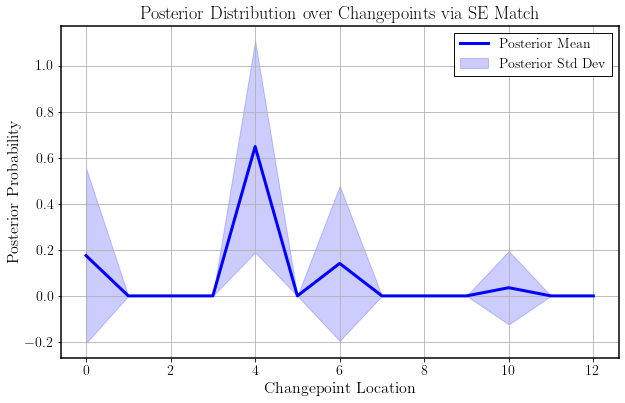

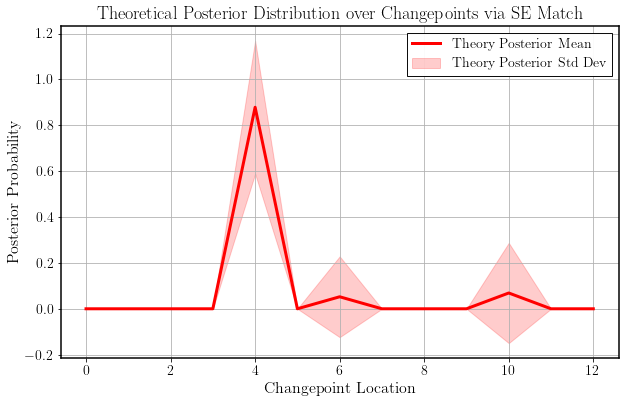

In [21]:
post_samples_mean = post_samples.mean(axis=0)
post_samples_std = post_samples.std(axis=0)

# Plot posterior mean and std
plt.figure(figsize=(10, 6))
plt.plot(np.arange(len(post_samples_mean)), post_samples_mean, label='Posterior Mean', color='blue')
plt.fill_between(np.arange(len(post_samples_mean)), post_samples_mean - post_samples_std, post_samples_mean + post_samples_std, color='blue', alpha=0.2, label='Posterior Std Dev')
plt.xlabel('Changepoint Location')
plt.ylabel('Posterior Probability')
plt.title('Posterior Distribution over Changepoints via SE Match')
plt.legend()
plt.grid()
plt.show()

# Plot theory posterior mean and std
theory_post_samples_mean = theory_post_samples.mean(axis=0)
theory_post_samples_std = theory_post_samples.std(axis=0)
plt.figure(figsize=(10, 6))
plt.plot(np.arange(len(theory_post_samples_mean)), theory_post_samples_mean, label='Theory Posterior Mean', color='red')
plt.fill_between(np.arange(len(theory_post_samples_mean)),
                 theory_post_samples_mean - theory_post_samples_std,
                 theory_post_samples_mean + theory_post_samples_std,
                 color='red', alpha=0.2, label='Theory Posterior Std Dev')
plt.xlabel('Changepoint Location')
plt.ylabel('Posterior Probability')
plt.title('Theoretical Posterior Distribution over Changepoints via SE Match')
plt.legend()
plt.grid()
plt.show()

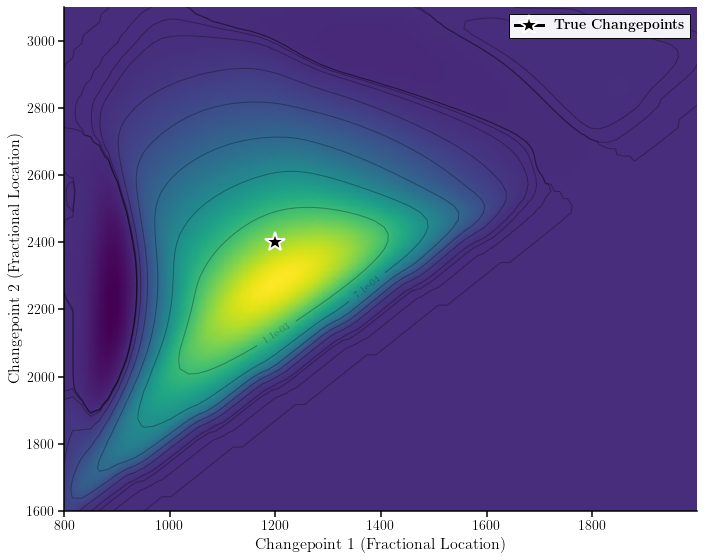

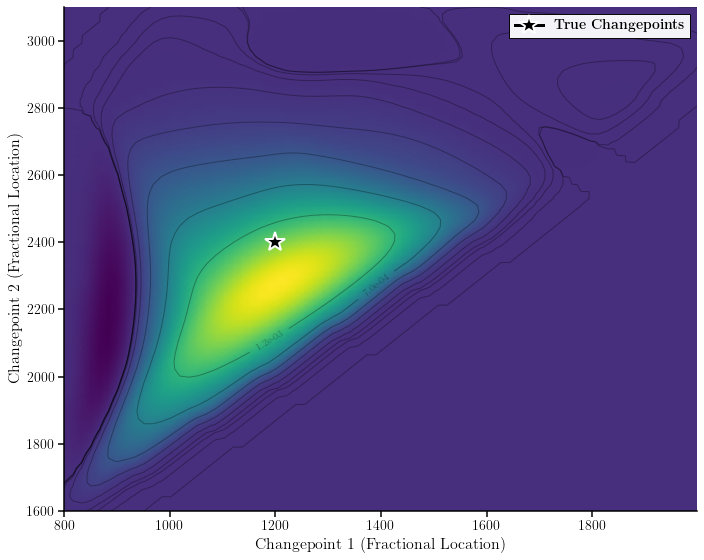

In [34]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.ndimage import gaussian_filter
from scipy.interpolate import griddata
import matplotlib.colors as mcolors
from matplotlib.patches import Rectangle

# Set up publication-ready plotting parameters
plt.rcParams.update({
    'font.size': 14,
    'font.family': 'serif',
    'font.serif': ['Computer Modern Roman', 'Times New Roman', 'DejaVu Serif'],
    'text.usetex': True,
    'axes.linewidth': 1.5,
    'axes.labelsize': 16,
    'axes.titlesize': 18,
    'xtick.labelsize': 14,
    'ytick.labelsize': 14,
    'legend.fontsize': 14,
    'legend.frameon': True,
    'legend.fancybox': False,
    'legend.edgecolor': 'black',
    'legend.framealpha': 0.95,
    'lines.linewidth': 3.0,
    'lines.markersize': 8,
    'figure.dpi': 72,
    'savefig.dpi': 300,
    'savefig.bbox': 'tight',
    'savefig.pad_inches': 0.1
})

# Paul Tol "Vibrant" palette
TOL_VIBRANT = ['#EE7733', '#0077BB', '#33BBEE', '#EE3377',
               '#CC3311', '#009988', '#BBBBBB', '#FF8800', '#DDAA33', '#BBCC33']

def plot_2d_posterior_heatmap(cp_grid, probabilities, 
                             sigma=1.0, 
                             grid_resolution=200,
                             true_changepoints=None,
                             title=None,
                             xlabel=r'Changepoint 1 (Fractional Location)',
                             ylabel=r'Changepoint 2 (Fractional Location)',
                             cmap='YlOrRd',
                             figsize=(10, 8),
                             show_colorbar=True,
                             contour_levels=10,
                             add_contours=True):
    """
    Plot a smoothed 2D posterior distribution as a heatmap.
    
    Parameters:
    -----------
    cp_grid : array-like, shape (n_points, 2)
        Grid of changepoint locations
    probabilities : array-like, shape (n_points,)
        Probability values for each point in cp_grid
    sigma : float
        Standard deviation for Gaussian smoothing kernel
    grid_resolution : int
        Resolution of the interpolated grid
    true_changepoints : tuple or list of tuples, optional
        True changepoint locations to mark on the plot
    title : str, optional
        Plot title
    xlabel, ylabel : str
        Axis labels
    cmap : str or matplotlib colormap
        Colormap for the heatmap
    figsize : tuple
        Figure size
    show_colorbar : bool
        Whether to show colorbar
    contour_levels : int
        Number of contour levels
    add_contours : bool
        Whether to add contour lines
    
    Returns:
    --------
    fig, ax : matplotlib figure and axis objects
    """
    
    # Create figure with proper styling
    fig, ax = plt.subplots(figsize=figsize)
    fig.patch.set_facecolor('white')
    
    # Extract x and y coordinates
    x = cp_grid[:, 0]
    y = cp_grid[:, 1]
    
    # Create a regular grid for interpolation
    xi = np.linspace(x.min(), x.max(), grid_resolution)
    yi = np.linspace(y.min(), y.max(), grid_resolution)
    Xi, Yi = np.meshgrid(xi, yi)
    
    # Interpolate the probabilities onto regular grid
    Zi = griddata((x, y), probabilities, (Xi, Yi), method='cubic', fill_value=0)
    
    # Apply Gaussian smoothing for KDE-like effect
    Zi_smooth = gaussian_filter(Zi, sigma=sigma)
    
    # Normalize to ensure it's a proper probability distribution
    Zi_smooth = Zi_smooth / np.sum(Zi_smooth)
    
    # Create the heatmap
    im = ax.pcolormesh(Xi, Yi, Zi_smooth, cmap=cmap, shading='gouraud')
    
    # Add contour lines if requested
    if add_contours:
        # Calculate contour levels based on probability quantiles
        prob_flat = Zi_smooth.flatten()
        prob_flat_sorted = np.sort(prob_flat[prob_flat > 0])
        if len(prob_flat_sorted) > contour_levels:
            level_indices = np.linspace(0, len(prob_flat_sorted)-1, contour_levels, dtype=int)
            levels = prob_flat_sorted[level_indices]
        else:
            levels = contour_levels
        
        contours = ax.contour(Xi, Yi, Zi_smooth, levels=levels, 
                             colors='black', alpha=0.3, linewidths=1.0)
        
        # Add contour labels for highest probability regions
        if len(contours.levels) > 3:
            ax.clabel(contours, contours.levels[-3:], inline=True, fontsize=10, fmt='%.1e')
    
    # Mark true changepoints if provided
    if true_changepoints is not None:
        if isinstance(true_changepoints, tuple) and len(true_changepoints) == 2:
            # Single pair of changepoints
            ax.plot(true_changepoints[0], true_changepoints[1], 
                   marker='*', markersize=20, color='black', 
                   markeredgecolor='white', markeredgewidth=2,
                   label=r'\textbf{True Changepoints}', zorder=100)
        else:
            # Multiple pairs
            for i, (cp1, cp2) in enumerate(true_changepoints):
                ax.plot(cp1, cp2, marker='*', markersize=20, color='black',
                       markeredgecolor='white', markeredgewidth=2,
                       label=r'\textbf{True Changepoint}' if i == 0 else "",
                       zorder=100)
    
    # Add colorbar if requested
    if show_colorbar:
        cbar = fig.colorbar(im, ax=ax, pad=0.02)
        cbar.set_label(r'Posterior Probability Density', fontsize=16)
        cbar.ax.tick_params(labelsize=12, width=1.5, length=6)
        cbar.outline.set_linewidth(1.5)
    
    # Set labels and title
    ax.set_xlabel(xlabel, fontsize=16)
    ax.set_ylabel(ylabel, fontsize=16)
    
    if title:
        ax.set_title(title, fontsize=18, pad=15)
    
    # Style the axes
    ax.tick_params(axis='both', which='major', width=1.5, length=6)
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    ax.spines['left'].set_linewidth(1.5)
    ax.spines['bottom'].set_linewidth(1.5)
    
    # Add legend if true changepoints were marked
    if true_changepoints is not None:
        ax.legend(loc='upper right', fontsize=14, frameon=True,
                 edgecolor='black', framealpha=0.95)
    
    # Set axis limits to data range
    ax.set_xlim(x.min(), x.max())
    ax.set_ylim(y.min(), y.max())
    
    plt.tight_layout()
    
    return fig, ax

cmap = 'viridis'
# cmap = 'cividis'
# cmap = 'Greys'

fig, ax = plot_2d_posterior_heatmap(cp_grid=cp_arr, 
                                    probabilities=post_samples.mean(axis=0),
                                    sigma=1.0,
                                    grid_resolution=72,
                                    true_changepoints=(fractional_chgpt_locations[0]*n, fractional_chgpt_locations[1]*n) if len(fractional_chgpt_locations) >= 2 else None,
                                    add_contours=True,
                                    show_colorbar=False,
                                    cmap=cmap,
                                    )

fig.savefig('figures/SE_match_posterior_Ls_empirical.pdf', bbox_inches='tight', dpi=300)
plt.show()
fig, ax = plot_2d_posterior_heatmap(cp_grid=cp_arr, 
                                    probabilities=theory_post_samples.mean(axis=0),
                                    sigma=1.0,
                                    grid_resolution=72,
                                    true_changepoints=(fractional_chgpt_locations[0]*n, fractional_chgpt_locations[1]*n) if len(fractional_chgpt_locations) >= 2 else None,
                                    add_contours=True,
                                    show_colorbar=False,
                                    cmap=cmap,
                                    )
fig.savefig('figures/SE_match_posterior_Ls_theoretical.pdf', bbox_inches='tight', dpi=300)
plt.show()


In [30]:
# Save experiment results using pickle
import pickle
experiment_results = {
    'cp_arr': cp_arr,
    'post_samples': post_samples,
    'theory_post_samples': theory_post_samples,
    'fractional_chgpt_locations': fractional_chgpt_locations,
    'n': n,
    'p': p,
    'L': L,
    'noise_std': noise_std,
    'true_chgpt_locations': true_chgpt_locations(n) if fractional_chgpt_locations.size != 0 else None,
    'B̃': B̃,
    'Sigma': Sigma,
    'Sigma_chol': Sigma_chol,
    'κ': κ,
    'B̃_cov': B̃_cov,
    'π': π,
    'delta': δ,
    'nu_arr': nu_arr,
    'kappa_arr': kappa_arr,
}
with open('results/Ls_experiment_1_results.pkl', 'wb') as f:
    pickle.dump(experiment_results, f)

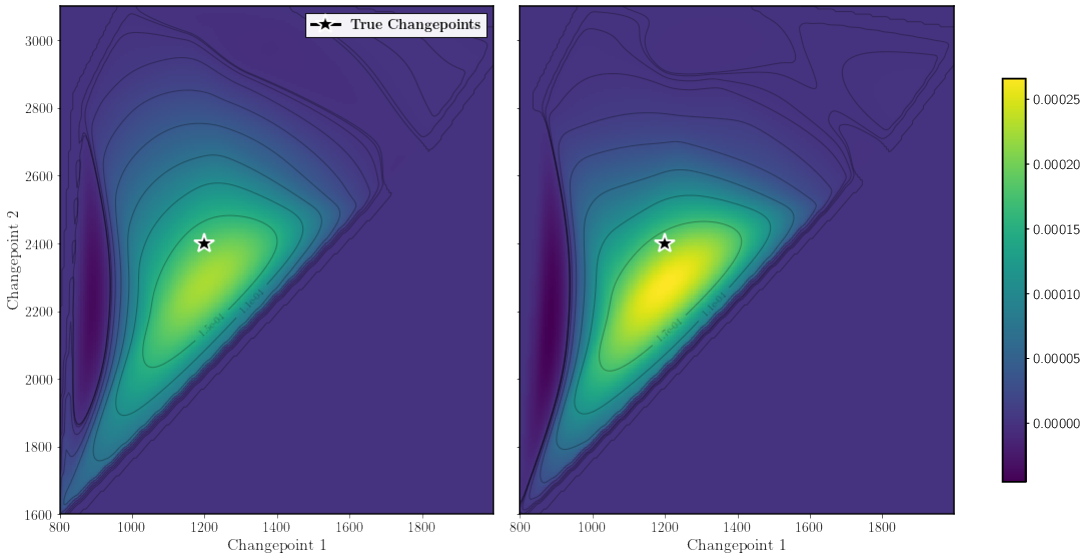

In [49]:
import numpy as np
import matplotlib

# Set the backend to PGF
matplotlib.use("pgf")
import matplotlib.pyplot as plt
from scipy.ndimage import gaussian_filter
from scipy.interpolate import griddata
from mpl_toolkits.axes_grid1 import make_axes_locatable

# Set up publication-ready plotting and PGF parameters
plt.rcParams.update({
    "pgf.texsystem": "pdflatex",
    'pgf.preamble': r'\usepackage[utf8x]{inputenc} \usepackage[T1]{fontenc} \usepackage{cmbright}',
    'font.size': 14,
    'font.family': 'serif',
    'text.usetex': True,
    'axes.linewidth': 1.5,
    'axes.labelsize': 16,
    'axes.titlesize': 18,
    'xtick.labelsize': 14,
    'ytick.labelsize': 14,
    'legend.fontsize': 14,
    'figure.dpi': 72,
    # savefig.dpi is now important for the rasterized part
    'savefig.dpi': 300,
})

def plot_posterior_comparison(
    cp_grid_empirical,
    probabilities_empirical,
    cp_grid_theory,
    probabilities_theory,
    sigma=1.0,
    grid_resolution=200,
    true_changepoints=None,
    title_empirical=None,
    title_theory=None,
    xlabel=r'Changepoint 1 (Fractional Location)',
    ylabel=r'Changepoint 2 (Fractional Location)',
    cmap='YlOrRd',
    figsize=(16, 8),
    contour_levels=10,
    add_contours=True,
    save_path_pgf=None,
    save_path_pdf=None
):
    """
    Plots two 2D posterior distributions side-by-side with a shared colorbar.
    The heatmaps are rasterized to avoid overwhelming the TeX engine.
    """
    fig, axes = plt.subplots(1, 2, figsize=figsize, sharey=True)
    fig.patch.set_facecolor('white')

    posteriors = [
        (cp_grid_empirical, probabilities_empirical, title_empirical),
        (cp_grid_theory, probabilities_theory, title_theory)
    ]

    images = []
    vmax = -np.inf
    vmin = np.inf

    # First pass to determine global min/max for color scaling
    for cp_grid, probabilities, _ in posteriors:
        x, y = cp_grid[:, 0], cp_grid[:, 1]
        xi = np.linspace(x.min(), x.max(), grid_resolution)
        yi = np.linspace(y.min(), y.max(), grid_resolution)
        Xi, Yi = np.meshgrid(xi, yi)
        Zi = griddata((x, y), probabilities, (Xi, Yi), method='cubic', fill_value=0)
        Zi_smooth = gaussian_filter(Zi, sigma=sigma)
        if np.sum(Zi_smooth) > 0:
            Zi_smooth /= np.sum(Zi_smooth)
        vmax, vmin = max(vmax, Zi_smooth.max()), min(vmin, Zi_smooth.min())

    # Second pass to plot
    for ax, (cp_grid, probabilities, title) in zip(axes, posteriors):
        x, y = cp_grid[:, 0], cp_grid[:, 1]
        xi = np.linspace(x.min(), x.max(), grid_resolution)
        yi = np.linspace(y.min(), y.max(), grid_resolution)
        Xi, Yi = np.meshgrid(xi, yi)
        Zi = griddata((x, y), probabilities, (Xi, Yi), method='cubic', fill_value=0)
        Zi_smooth = gaussian_filter(Zi, sigma=sigma)
        if np.sum(Zi_smooth) > 0:
            Zi_smooth /= np.sum(Zi_smooth)

        # Use 'auto' shading which is supported and efficient
        im = ax.pcolormesh(Xi, Yi, Zi_smooth, cmap=cmap, shading='auto', vmin=vmin, vmax=vmax)
        images.append(im)
        
        # --- THIS IS THE FIX ---
        # Rasterize the heatmap to prevent overwhelming LaTeX
        ax.set_rasterized(True)
        # ---------------------

        if add_contours:
            prob_flat = Zi_smooth.flatten()
            prob_flat_sorted = np.sort(prob_flat[prob_flat > 0])
            if len(prob_flat_sorted) > contour_levels:
                level_indices = np.linspace(0, len(prob_flat_sorted) - 1, contour_levels, dtype=int)
                levels = prob_flat_sorted[level_indices]
            else:
                levels = contour_levels
            
            contours = ax.contour(Xi, Yi, Zi_smooth, levels=levels, colors='black', alpha=0.3, linewidths=1.0)
            
            if len(contours.levels) > 3:
                ax.clabel(contours, contours.levels[-3:], inline=True, fontsize=10, fmt='%.1e')

        if true_changepoints:
            ax.plot(true_changepoints[0], true_changepoints[1], marker='*', markersize=20, color='black',
                    markeredgecolor='white', markeredgewidth=2, label=r'\textbf{True Changepoints}', zorder=100)

        ax.set_xlabel(xlabel)
        if title:
            ax.set_title(title)
        ax.set_xlim(x.min(), x.max())
        ax.set_ylim(y.min(), y.max())

    axes[0].set_ylabel(ylabel)
    if true_changepoints:
        axes[0].legend(loc='upper right')

    fig.subplots_adjust(right=0.85)
    cbar_ax = fig.add_axes([0.88, 0.15, 0.02, 0.7])
    fig.colorbar(images[0], cax=cbar_ax)

    plt.tight_layout(rect=[0, 0, 0.85, 1])

    # Save the figure in multiple formats if paths are provided
    if save_path_pgf:
        print(f"Saving PGF figure to {save_path_pgf}...")
        # The dpi here controls the resolution of the rasterized heatmap
        fig.savefig(save_path_pgf, dpi=300)
        print("Done.")
    if save_path_pdf:
        print(f"Saving PDF figure to {save_path_pdf}...")
        fig.savefig(save_path_pdf, dpi=300)
        print("Done.")

    # plt.show()
    return fig, axes

fig, axes = plot_posterior_comparison(
    cp_arr,
    post_samples.mean(axis=0),
    cp_arr,
    theory_post_samples.mean(axis=0),
    sigma=1.0,
    grid_resolution=200,
    true_changepoints=(fractional_chgpt_locations[0]*n, fractional_chgpt_locations[1]*n) if len(fractional_chgpt_locations) >= 2 else None,
    title_empirical=None,
    title_theory=None,
    xlabel=r'Changepoint 1',
    ylabel=r'Changepoint 2',
    cmap='viridis',
    figsize=(16, 8),
    contour_levels=10,
    add_contours=True
)
fig.savefig('figures/SE_match_posterior_Ls_comparison.pdf', bbox_inches='tight', dpi=300)
fig.savefig('figures/SE_match_posterior_Ls_comparison.pgf', bbox_inches='tight', dpi=300)
# Do the matplot inline so that I can view plots in jupyter notebook
%matplotlib inline
plt.show()

# SE match posterior: logistic number of change points

\Delta: 20, n: 100, Lmin: 1, Lmax: 2


  0%|          | 0/2 [00:00<?, ?it/s]

  0%|          | 0/1 [00:00<?, ?it/s]

  0%|          | 0/58 [00:00<?, ?it/s]

Sum of row weights:  [5979.80051161 2020.19948839]


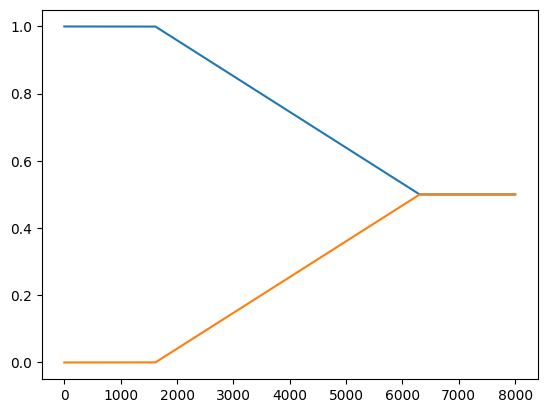

Computing fixed point soln for all L = 2


  0%|          | 0/10 [00:00<?, ?it/s]

Computing fixed point solution for no cp
Success status for no cp fixed point:  False
Success status for true cp fixed point:  False


  0%|          | 0/30 [00:00<?, ?it/s]

\Delta: 10, n: 50, Lmin: 1, Lmax: 2


  0%|          | 0/2 [00:00<?, ?it/s]

... (205 outputs left out)

Binary segmentation - searching for best L:   0%|          | 0/2 [00:00<?, ?it/s]

  Tested 7999 valid positions
  Best 5 improvements: [(3974, Array(799.25174757, dtype=float64), Array(4170.64683708, dtype=float64)), (3983, Array(799.01383337, dtype=float64), Array(4170.88475129, dtype=float64)), (3999, Array(798.97314746, dtype=float64), Array(4170.92543719, dtype=float64)), (3988, Array(798.97041167, dtype=float64), Array(4170.92817298, dtype=float64)), (3986, Array(798.96896899, dtype=float64), Array(4170.92961566, dtype=float64))]

Applying local refinement...
b_hat, b:  [0.9235457  3.53317412] [0.93593217 3.40711714]


100%|██████████| 30/30 [04:52<00:00,  9.74s/it]

Theta cov:  [[1.02656592 0.79456641]
 [0.79456641 2.570039  ]]
V.T @ V / n:  [[1.08120356 0.75937733]
 [0.75937733 2.18764135]]
nu.T @ ρ @ nu + kappa:  [[1.09425598 0.78683084]
 [0.78683084 2.25314323]]


In [10]:
from WERM.config import unif_prior_to_η_ϕ
from WERM.config import η_to_ψ
from WERM.signal_priors import GaussianSignal
import WERM.model as model
import WERM.general_fixed_point_eqns as fp
import WERM.M_est_fixed_point_eqns as M_est
import WERM.gof
import WERM.performance_measures
import WERM.general_fixed_point_eqns as fp
import WERM.marginals
import WERM.config
import numpy as np
import jax.numpy as jnp # Not used in any randomness, all randomness is in numpy
import jax
import numpy.random as nprandom
import matplotlib.pyplot as plt
import scipy
from sklearn import linear_model
from functools import partial
from tqdm import tqdm
import time
tqdm = partial(tqdm, position=0, leave=True)
import jax.random
import importlib
import WERM.estimators
importlib.reload(WERM.estimators)
importlib.reload(fp)
import WERM.posterior
importlib.reload(WERM.posterior)

# Set numpy random seed for reproducibility
random_seed = 42
np.random.seed(random_seed)
# Master PRNG key for reproducibility of all runs
MASTER_KEY = jax.random.PRNGKey(random_seed)

p = 1000 #8000, 1000 on the last one
L = 2 # num signals. L-1 changepoints
noise_std = 1.0 # Placeholder, not used for logistic regression

# Least Squares Loss
# M = lambda u, v: jnp.power(u - v, 2)

# Huber Loss
# def M(u, v, epsilon=1.35):
#     residual = u - v
#     abs_residual = jnp.abs(residual)
#     condition = abs_residual <= epsilon
#     squared_loss = 0.5 * jnp.square(residual)
#     linear_loss = epsilon * (abs_residual - 0.5 * epsilon)
#     return jnp.where(condition, squared_loss, linear_loss)

# Logistic loss
M = lambda u, v: jnp.log(1 + jnp.exp(u)) - jnp.multiply(v, u)
num_trials = 30

# fractional_chgpt_locations = np.array([0.33333, 0.666667])
fractional_chgpt_locations = np.array([0.5])
# fractional_chgpt_locations = np.array([])
# fractional_chgpt_locations = np.array([])
# chgpt_locations = np.array([])

δ = 8.0 # Exp 1 is 4.0
n = int(δ * p)
if fractional_chgpt_locations.size != 0:
    true_chgpt_locations = lambda n: (n*fractional_chgpt_locations).astype(int)
    C_true = η_to_ψ(true_chgpt_locations(n), n)
else:
    true_chgpt_locations = lambda n: np.array([])
    C_true = np.zeros(n).astype(int) # No changepoint, assume signal 1, not 0. 

# --- Preliminaries ---
# --- Compute weights as marginals of prior --- #
Δ = lambda n: int(n/5)
Delta_n = int(Δ(n))
L_is_upper_bound = True
if Delta_n ==1 : # No separation between change points, so use analytical binomial approximation. 
    if L_is_upper_bound:
        pi_i_l = lambda L, l, i : 1/(L - l + 1) * np.sum([scipy.special.comb(k - 1, l- 1, exact=False) * (i/n)**(l-1) * (1 - i/n)**(k-l) for k in range(l, L+1)])
    else: 
        pi_i_l = lambda L,l , i: scipy.special.comb(L-1, l-1, exact=False) * (i/n)**(l-1) * (1 - i/n)**(L-l)
    # Populate the pi L times n matrix
    pi = np.zeros((L, n))
    for l in range(L):
        for i in range(n):
            pi[l, i] = pi_i_l(L, l + 1, i + 1)
else: 
    n_small = 100
    Delta_n_small = int(Delta_n * n_small/n)
    if L_is_upper_bound: 
        p_l = 1/L * np.ones(L) # puts equal weight on all number of signals, set None otherwise. Best for estimating size. 
        Lmin = 1
        Lmax = L
    else:
        p_l = None
        Lmin = L
        Lmax = L
    pi = WERM.config.extrapolated_marginals(Lmin, Lmax, Delta_n_small, n_small = n_small, n_large = n, p_l = p_l, verbose = False)
π = pi
if L == 1: 
    π = np.ones((1, n))
print("Sum of row weights: ", π.sum(axis=1))
# # Normalize rows to sum to 1
# row_sums = π.sum(axis=1, keepdims=True)
# π = π / row_sums
# Plot pi
plt.plot(π.T)
plt.show()

    
# Draw Sigma from an AR(1) process for some correlation structure r_s = 0.5
r_s = 0.1
AR1 = np.fromfunction(lambda i, j: r_s**(np.abs(i - j)), (p, p))
Sigma = AR1
Sigma_chol = np.linalg.cholesky(Sigma + 1e-12 * np.eye(p)) # Add small ridge for numerical stability

# Gaussian Signal Prior
κ = 1.0
B̃_cov = κ**2 * δ * np.eye(L) # keeps the signal power fixed
B̃_cov[0, 1] = -0.8 * κ**2 * δ  # Introduce some correlation between the first two signals
B̃_cov[1, 0] = -0.8 * κ**2 * δ  # Introduce some correlation between the first two signals
# B̃_cov = κ**2 * δ * np.array([[1.0, 0.0], [0.0, 1.0]]) # keeps the signal power fixed
signal_prior = GaussianSignal(B̃_cov)

B̃ = signal_prior.sample(p)
# Compute fixed point solution once per delta for theoretical comparison
ρ = (1/δ) * (1/p) * (B̃.T @ Sigma_chol @ Sigma_chol.T @ B̃)
key = jax.random.PRNGKey(0)

model_q = model.q_logistic_model
ε = np.random.uniform(0, 1, size=(n, ))

# all_fp_solns = fp.compute_all_fixed_points(n, L, Δ(n), M, ρ, δ, π, ε, n, model_q, MASTER_KEY, coarse_grain_factor=500)
# all_fp_solns = fp.compute_all_fixed_points_vmap(n, L, Δ(n), M, ρ, δ, π, ε, n, model_q, MASTER_KEY, coarse_grain_factor=80000, batch_size=1, max_iter=1000, fp_lr=0.05, use_polyak_avg=True, early_stop_tol=1e-5)
print("Computing fixed point soln for all L = 2")
# all_fp_solns_L1 = fp.compute_all_fixed_points_naive(n, 2, Δ(n), M, ρ, δ, π, ε, model_q, coarse_grain_factor=10000, master_key=MASTER_KEY, maxiter=150)
# all_fp_solns_L2 = fp.compute_all_fixed_points_naive(n, 3, Δ(n), M, ρ, δ, π, ε, model_q, coarse_grain_factor=1000, master_key=MASTER_KEY, maxiter=150)
all_fp_solns = fp.compute_all_fixed_points_naive(n, L, Δ(n), M, ρ, δ, π, ε, model_q, coarse_grain_factor=500, master_key=MASTER_KEY, maxiter=500)
print("Computing fixed point solution for no cp")
b_L0, nu_L0, kappa_L0, success_status_L0 = fp.compute_single_fixed_point(np.array([]), M, ρ, δ, π, ε, n, model_q, MASTER_KEY, maxiter=500)
print("Success status for no cp fixed point: ", success_status_L0)
b, nu, kappa, success_status = fp.compute_single_fixed_point(true_chgpt_locations(n), M, ρ, δ, π, ε, n, model_q, MASTER_KEY, maxiter=500)
print("Success status for true cp fixed point: ", success_status)
# all_fp_solns = all_fp_solns_naive
cp_arr = np.array([lis[0] for lis in all_fp_solns])
nu_arr = np.array([lis[2] for lis in all_fp_solns]).reshape((-1, L, L))
kappa_arr = np.array([lis[3] for lis in all_fp_solns]).reshape((-1, L, L))
p_η_arr = np.ones((len(cp_arr),)) / len(cp_arr)  # Uniform prior over changepoint

cp_arr_L0 = np.array([-1]).reshape((1, 1))
nu_arr_L0 = np.array([nu_L0]).reshape((1, L, L))
kappa_arr_L0 = np.array([kappa_L0]).reshape((1, L, L))
p_η_arr_L0 = np.array([1.0]).reshape((1,))  #

post_samples = np.zeros((num_trials, len(cp_arr)))
theory_post_samples = np.zeros((num_trials, len(cp_arr)))

post_samples_L0 = np.zeros((num_trials, 1))
theory_post_samples_L0 = np.zeros((num_trials, 1))

for trial_num in tqdm(range(num_trials)):
    # Generate the observation vector Y
    X = np.random.normal(0, np.sqrt(1/n), (n, p))
    X = X @ Sigma_chol.T  # Introduce correlation structure in features

    # ε = jax.random.t(key, 5, shape=(n, ))
    # ε = np.random.standard_t(5, size=(n, ))

    Θ = X @ B̃
    # y = lin_reg(Θ, C_true, noise_std).astype(np.float64).flatten()
    y_fn = jax.vmap(model_q, in_axes=(0, 0, 0), out_axes=0)
    y = y_fn(Θ, C_true, ε)
    # y = jax.vmap(model.q_logistic_model, in_axes = (0, 0, 0))(Θ, C_true, ε)

    cp, gof, B̂ = WERM.estimators.weighted_erm(X, y, M, L, Δ(n), 0.0, L_is_upper_bound=L_is_upper_bound, brute_force=False, 
                                               return_gof=True, return_B_hat=True)
    

    Theta_hat = X @ B̂
    Theta_deb, b_hat = WERM.posterior.compute_debiased_theta(Theta_hat, y, M, π, δ, output_b_hat=True,
                                                             history_size=5, ridge=1e-8, maxiter=1000, learning_rate=0.3, use_iterate_averaging=True)
    print("b_hat, b: ", b_hat, b)


    σ = noise_std
    posterior = WERM.posterior.exact_posterior_logistic(cp_arr.astype(float), p_η_arr, Theta_deb, y, ρ, σ, nu_arr, kappa_arr, normalize=False)
    posterior_L0 = WERM.posterior.exact_posterior_logistic(cp_arr_L0.astype(float), p_η_arr_L0, Theta_deb, y, ρ, σ, nu_arr_L0, kappa_arr_L0, normalize=False)
    post_samples[trial_num, :] = posterior
    post_samples_L0[trial_num, :] = posterior_L0

    # Try theoretical posterior to see if matches
    Z = np.random.multivariate_normal(np.zeros(L), ρ, size=n)
    G_Theta = np.random.multivariate_normal(np.zeros(L), kappa, size=n)
    V = Z @ nu + G_Theta
    y_bar = y_fn(Z, C_true, ε)
    theory_post = WERM.posterior.exact_posterior_logistic(cp_arr, p_η_arr, V, y_bar, ρ, σ, nu_arr, kappa_arr, normalize=False)
    theory_post_L0 = WERM.posterior.exact_posterior_logistic(cp_arr_L0, p_η_arr_L0, V, y_bar, ρ, σ, nu_arr_L0, kappa_arr_L0, normalize=False)
    theory_post_samples[trial_num, :] = theory_post
    theory_post_samples_L0[trial_num, :] = theory_post_L0

    # Sanity check: posterior should integrate to 1
    print("Theta cov: ", Theta_deb.T @ Theta_deb / n)
    print("V.T @ V / n: ", V.T @ V / n)
    print("nu.T @ ρ @ nu + kappa: ", nu.T @ ρ @ nu + kappa)


In [13]:
posterior.sum()
theory_post.sum()

Array(0.1, dtype=float64)

In [14]:
posterior_L0

Array([1.], dtype=float64)

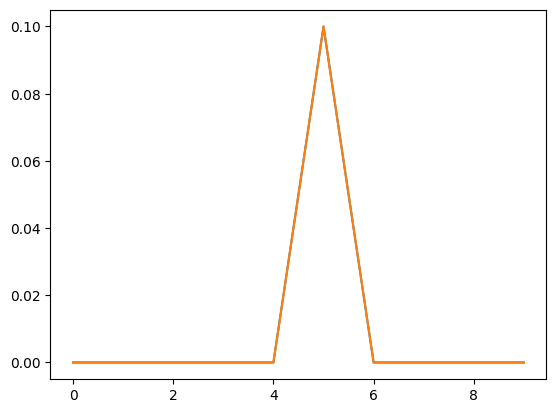

In [16]:
plt.plot(posterior)
plt.plot(theory_post)

In [5]:
theory_post_L0

Array([1.], dtype=float64)

In [15]:
posterior.sum()

Array(0.1, dtype=float64)

In [6]:
theory_post.sum()

Array(0.08333333, dtype=float64)

In [9]:
all_fp_solns

[(array([2000]),
  Array([0.80811898, 1.4901524 ], dtype=float64),
  Array([[0.31658053, 0.2931204 ],
         [0.85542965, 1.17167711]], dtype=float64),
  Array([[0.80627218, 0.29747826],
         [0.29747826, 0.36457005]], dtype=float64),
  Array(False, dtype=bool)),
 (array([2500]),
  Array([0.89943733, 1.72916078], dtype=float64),
  Array([[0.56033639, 0.32165065],
         [0.94429468, 1.21416324]], dtype=float64),
  Array([[1.0206828 , 0.38996954],
         [0.38996954, 0.4855756 ]], dtype=float64),
  Array(False, dtype=bool)),
 (array([3000]),
  Array([0.6538239 , 1.93106286], dtype=float64),
  Array([[0.58760887, 0.20352523],
         [0.81372791, 1.2231157 ]], dtype=float64),
  Array([[0.52888523, 0.31919175],
         [0.31919175, 0.60383852]], dtype=float64),
  Array(False, dtype=bool)),
 (array([3500]),
  Array([0.7709438 , 1.44653905], dtype=float64),
  Array([[0.41742832, 0.25612954],
         [0.59386207, 1.17647985]], dtype=float64),
  Array([[0.75109201, 0.28666241],
 